In [1]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

df = pd.read_csv("/Applications/MAMP/htdocs/local/kodingakademi/Python/bootcamp data analis/pertemuan/ML/Mall_Customers.csv")
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [2]:
x = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = MinMaxScaler()
x_scaled = scaler.fit_transform(x)

x_scaled

array([[0.        , 0.3877551 ],
       [0.        , 0.81632653],
       [0.00819672, 0.05102041],
       [0.00819672, 0.7755102 ],
       [0.01639344, 0.39795918],
       [0.01639344, 0.76530612],
       [0.02459016, 0.05102041],
       [0.02459016, 0.94897959],
       [0.03278689, 0.02040816],
       [0.03278689, 0.7244898 ],
       [0.03278689, 0.13265306],
       [0.03278689, 1.        ],
       [0.04098361, 0.14285714],
       [0.04098361, 0.7755102 ],
       [0.04098361, 0.12244898],
       [0.04098361, 0.79591837],
       [0.04918033, 0.34693878],
       [0.04918033, 0.66326531],
       [0.06557377, 0.28571429],
       [0.06557377, 0.98979592],
       [0.07377049, 0.34693878],
       [0.07377049, 0.73469388],
       [0.08196721, 0.04081633],
       [0.08196721, 0.73469388],
       [0.10655738, 0.13265306],
       [0.10655738, 0.82653061],
       [0.10655738, 0.31632653],
       [0.10655738, 0.6122449 ],
       [0.1147541 , 0.30612245],
       [0.1147541 , 0.87755102],
       [0.

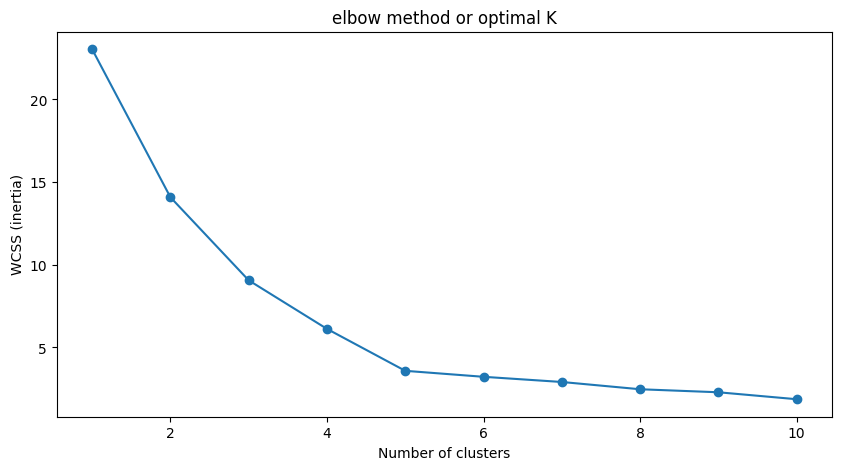

In [4]:
wcss = []
for i in range(1, 11): 
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10,5))
plt.plot(range(1,11), wcss, marker="o")
plt.title("elbow method or optimal K")
plt.xlabel("Number of clusters")
plt.ylabel("WCSS (inertia)")
plt.show()

In [5]:
k = 5
kmeans = KMeans(n_clusters=k, init="k-means++", n_init = 10, max_iter = 300, random_state=42)
df["cluster"] = kmeans.fit_predict(x_scaled)
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,0
2,3,Female,20,16,6,4
3,4,Female,23,16,77,0
4,5,Female,31,17,40,4
...,...,...,...,...,...,...
195,196,Female,35,120,79,2
196,197,Female,45,126,28,1
197,198,Male,32,126,74,2
198,199,Male,32,137,18,1


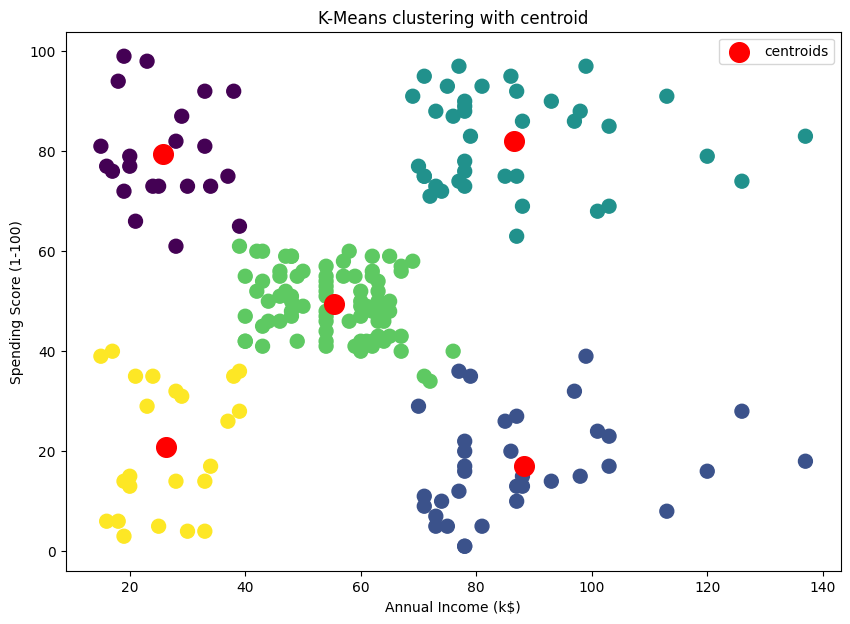

In [13]:
centroids = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids)

plt.figure(figsize=(10,7))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c = df["cluster"], s = 100)
plt.scatter(centroids_original[:, 0], centroids_original[:, 1], s = 200, c = "red", label = "centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("K-Means clustering with centroid")
plt.legend()
plt.show()

In [14]:
score = silhouette_score(x_scaled, df["cluster"])
print(f"Skor = {score:.2f}")

Skor = 0.56
